# Simple Multimodal Test - Variational Inference

Compare 3 models to assess performance:

1. Trained only one one modality
2. Trained jointly on all modalities as vector output
3. One main model with separate models for other modalities as additional input

**Fit using Variational Inference**, with the custom guide defined in this package.

In [1]:
import logging
import numpy as np
import torch
import itertools
import matplotlib.pyplot as plt
import pyro
from pyro.infer import NUTS, MCMC, Predictive
from pyro.infer.autoguide import init_to_sample
import pyro.distributions as dist
from pyro.contrib.autoname import scope
import math
import statistics

import mmbo.examples.testfunc as testfunc
from mmbo.nn import TIBNN, LayeredTIBNN, TIBNNGuide


In [20]:
# Consistent network parameters
width = 400
depth = 2
output_bias = True
bias_ordering = False
bias_positive = False
residual_prior = dist.Exponential(5)
#residual_prior = dist.LogNormal(np.log(0.1), np.log(np.sqrt(10)))
#residual_prior = dist.HalfCauchy(1)

# Consistent sampling parameters
warmup_steps = 150
num_samples = 50
num_chains = 2

In [3]:
def plot_predictions(model, guide, x_plot, y_plot, x_train, y_train, pred_site="mu", num_samples = 100):
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [1.05*x_plot.min() - 0.05*x_plot.max(), 1.05*x_plot.max() - 0.05*x_plot.min()]
    ylims = [1.5*y_plot.min() - 0.5*y_plot.max(), 1.5*y_plot.max() - 0.5*y_plot.min()]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)
    # Plot predicted means
    preds = Predictive(model, guide = guide, return_sites=[pred_site], num_samples=num_samples)(x_plot)
    for inst in range(preds[pred_site].shape[0]):
        y_inst = preds[pred_site][inst,:,-1]
        ax.plot(x_plot.squeeze(), y_inst, '-', linewidth=0.5, alpha=0.2, color="red", zorder = 0)
    # Plot confidence bands
    y_pred_mean = preds[pred_site].mean(0)[:,-1]
    y_pred_std = preds[pred_site].std(0)[:,-1]
    ax.plot(x_plot.squeeze(), y_pred_mean, '-', linewidth=3, color="#408765", label="predictive mean", zorder = 10)
    ax.fill_between(x_plot.squeeze(), y_pred_mean - 2 * y_pred_std, y_pred_mean + 2 * y_pred_std, alpha=0.6, color='#86cfac', zorder=5)
    # Plot true function
    ax.plot(x_plot.squeeze(), y_plot.squeeze(), 'b-', linewidth=3, label="true function", zorder = 15)
    # Plot data points
    ax.plot(x_train.squeeze(), y_train.squeeze(), 'ko', markersize=4, label="observations", zorder = 20)
    plt.legend(loc="lower right")

## Generate test data

In [4]:
def _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    rng = np.random.default_rng(seed)
    ntrain = ntrainpergroup * (2 ** len(modes) - 1)
    # Training Data
    X_train = np.linspace(xmin, xmax, num=ntrain)
    if shuffle:
        rng.shuffle(X_train)
    Y_train = np.empty((ntrain, len(modes)))
    Y_train.fill(np.nan)
    combinations = list(itertools.chain.from_iterable([itertools.combinations(range(len(modes)), r) for r in range(1,len(modes)+1)])) * ntrainpergroup
    for r in range(ntrain):
        for c in combinations[r]:
            Y_train[r,c] = func(X_train[r], modes[c])
    Y_train_full = np.zeros((ntrain, len(modes)))
    for i,m in enumerate(modes):
        Y_train_full[:,i] = func(X_train, m)
    # Package and return
    X_train_pt = torch.Tensor(np.float32(X_train.reshape((ntrain,1))))
    Y_train_pt = torch.Tensor(np.float32(Y_train))
    Y_train_full_pt = torch.Tensor(np.float32(Y_train_full))
    if full:
        return X_train_pt, Y_train_pt, Y_train_full_pt
    else:
        return X_train_pt, Y_train_pt

def _molecule_train_data(func, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    modes = func.modes
    return _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle)

def li2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.li2_energy, 0.5, 11.0, ntrainpergroup, seed, full, shuffle)

def be2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.be2_energy, 0.5, 5.0, ntrainpergroup, seed, full, shuffle)

def nice_periodic_train_data(ntrainpergroup, nummodes=5, seed=None, full=False, shuffle=True):
    return _train_data(testfunc.nice_periodic, list(range(nummodes)), -np.pi, np.pi, ntrainpergroup, seed, full, shuffle)

Text(0.5, 1.0, 'Training Data')

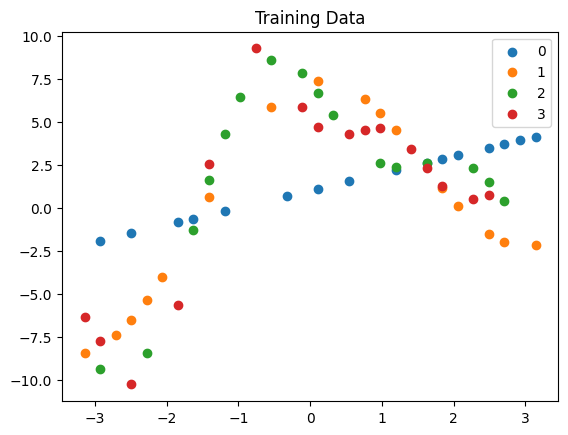

In [5]:
n_modes = 4

X_train, Y_train, Y_train_full = nice_periodic_train_data(2, n_modes, 1234, full=True)

X_plot, _, Y_plot = nice_periodic_train_data(100, n_modes, 1234, full=True, shuffle=False)

for i,m in enumerate(range(n_modes)):
    plt.scatter(X_train.detach(), Y_train.detach()[:,i], label=m)
plt.legend(loc="upper right")
plt.title("Training Data")

In [6]:
pyro.set_rng_seed(2024)

In [7]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, **kwargs):
    losses = []
    current_loss = current_loss_std = None
    nonimproved = 0
    while nonimproved < max_nonimproved:
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if (len(losses)+1) % check_interval == 0:
            previous_loss, previous_loss_std = current_loss, current_loss_std
            current_loss = statistics.mean(losses[-check_interval:])
            current_loss_std = statistics.stdev(losses[-check_interval:])
            if (previous_loss is not None) and (current_loss + current_loss_std/math.sqrt(check_interval) > previous_loss - previous_loss_std/math.sqrt(check_interval)):
                nonimproved += 1
            else:
                nonimproved = 0
            logging.info("Step {} Average Elbo loss: {:.1f} (+/- {:.3f}) {}".format(len(losses), current_loss, current_loss_std/math.sqrt(check_interval), '*'*nonimproved))
    return losses

## 1. Single Modality Model

In [21]:
single = TIBNN.from_data(X_train, Y_train[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

#single_guide = TIBNNGuide(single)
single_guide = pyro.infer.autoguide.AutoNormal(single)

logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

#auto_guide = model.guide()
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 2)
single_svi = pyro.infer.SVI(single, single_guide, adam, elbo)

losses = do_svi(single_svi, X_train, Y_train, check_interval = 500)

plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

Step 499 Average Elbo loss: 84105.6 (+/- 1065.562) 
Step 999 Average Elbo loss: 32632.6 (+/- 380.814) 
Step 1499 Average Elbo loss: 13598.5 (+/- 146.189) 
Step 1999 Average Elbo loss: 6219.7 (+/- 57.384) 
Step 2499 Average Elbo loss: 3310.3 (+/- 22.813) 
Step 2999 Average Elbo loss: 2128.8 (+/- 9.942) 
Step 3499 Average Elbo loss: 1578.4 (+/- 5.373) 
Step 3999 Average Elbo loss: 1267.9 (+/- 3.385) 
Step 4499 Average Elbo loss: 1063.5 (+/- 2.416) 
Step 4999 Average Elbo loss: 938.2 (+/- 1.725) 
Step 5499 Average Elbo loss: 866.3 (+/- 1.299) 
Step 5999 Average Elbo loss: 833.5 (+/- 1.195) 
Step 6499 Average Elbo loss: 821.0 (+/- 1.115) 
Step 6999 Average Elbo loss: 818.9 (+/- 1.144) *
Step 7499 Average Elbo loss: 816.7 (+/- 1.138) **
Step 7999 Average Elbo loss: 818.2 (+/- 1.035) ***


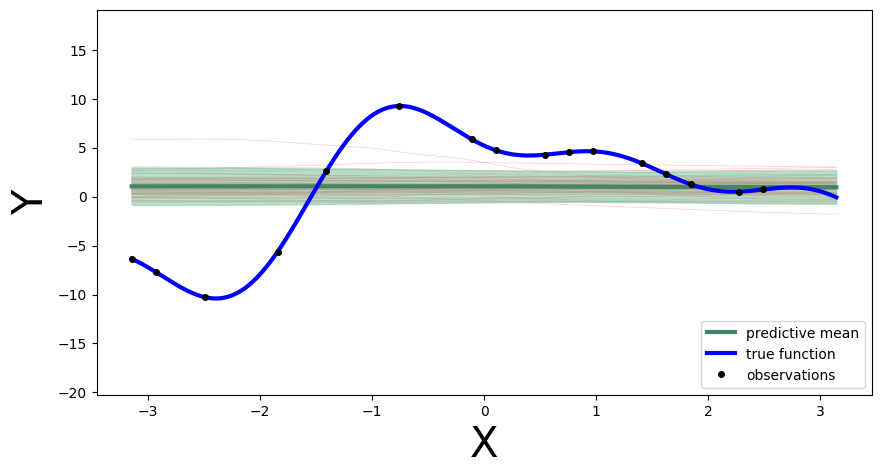

In [25]:
plot_predictions(single, single_guide, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:])

## 2. Joint output Model

Step 499 Average Elbo loss: 84396.0 (+/- 1076.776) 
Step 999 Average Elbo loss: 32388.5 (+/- 383.253) 
Step 1499 Average Elbo loss: 13199.8 (+/- 147.747) 
Step 1999 Average Elbo loss: 5734.9 (+/- 58.083) 
Step 2499 Average Elbo loss: 2789.7 (+/- 23.017) 
Step 2999 Average Elbo loss: 1627.8 (+/- 9.338) 
Step 3499 Average Elbo loss: 1154.2 (+/- 4.034) 
Step 3999 Average Elbo loss: 961.0 (+/- 1.887) 
Step 4499 Average Elbo loss: 884.3 (+/- 1.224) 
Step 4999 Average Elbo loss: 859.4 (+/- 1.106) 
Step 5499 Average Elbo loss: 853.9 (+/- 1.070) 
Step 5999 Average Elbo loss: 855.8 (+/- 1.149) *
Step 6499 Average Elbo loss: 857.6 (+/- 1.114) **
Step 6999 Average Elbo loss: 858.9 (+/- 1.125) ***


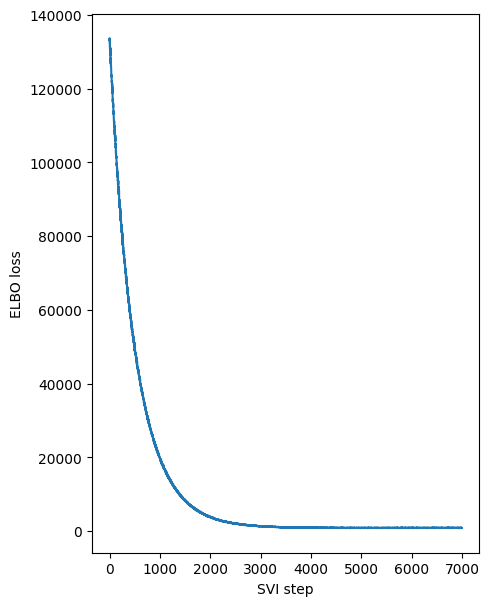

In [26]:
multiple = TIBNN.from_data(X_train, Y_train, width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

multiple_guide = pyro.infer.autoguide.AutoNormal(multiple)

logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

#auto_guide = model.guide()
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 2)
multiple_svi = pyro.infer.SVI(multiple, multiple_guide, adam, elbo)

losses = do_svi(multiple_svi, X_train, Y_train, check_interval = 500)

plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

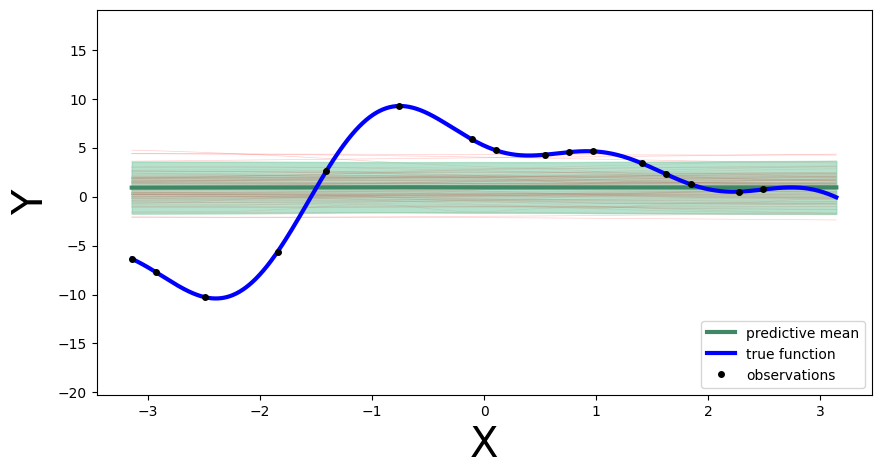

In [28]:
plot_predictions(multiple, multiple_guide, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:])

## 3. Separate Model with Predictors

Step 499 Average Elbo loss: 169119.6 (+/- 2144.923) 
Step 999 Average Elbo loss: 65396.0 (+/- 767.202) 
Step 1499 Average Elbo loss: 26804.4 (+/- 298.800) 
Step 1999 Average Elbo loss: 11568.4 (+/- 120.088) 
Step 2499 Average Elbo loss: 5417.7 (+/- 48.681) 
Step 2999 Average Elbo loss: 2943.4 (+/- 19.571) 
Step 3499 Average Elbo loss: 1959.1 (+/- 7.827) 
Step 3999 Average Elbo loss: 1589.6 (+/- 3.072) 
Step 4499 Average Elbo loss: 1471.5 (+/- 1.683) 
Step 4999 Average Elbo loss: 1446.6 (+/- 1.596) 
Step 5499 Average Elbo loss: 1446.4 (+/- 1.620) *
Step 5999 Average Elbo loss: 1452.7 (+/- 1.631) **
Step 6499 Average Elbo loss: 1456.3 (+/- 1.515) ***


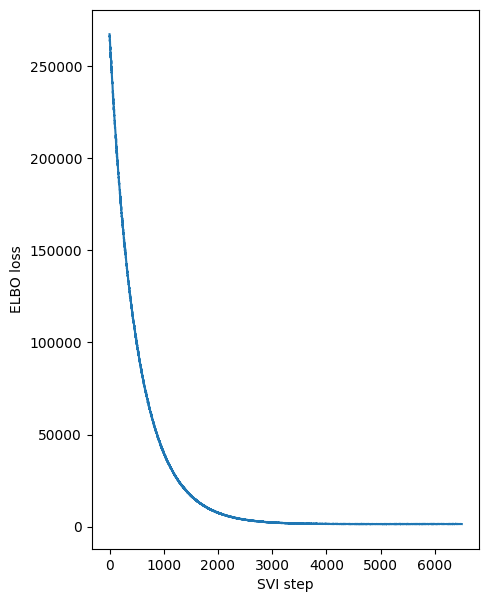

In [30]:
layered = LayeredTIBNN.from_data(X_train, Y_train[:,:-1], Y_train[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

layered_guide = pyro.infer.autoguide.AutoNormal(layered)

logging.basicConfig(format='%(message)s', level=logging.INFO)

pyro.clear_param_store()

#auto_guide = model.guide()
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 2)
layered_svi = pyro.infer.SVI(layered, layered_guide, adam, elbo)

losses = do_svi(layered_svi, X_train, Y_train[:,:-1], Y_train[:,-1:], check_interval = 500)

plt.figure(figsize=(5, 7))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

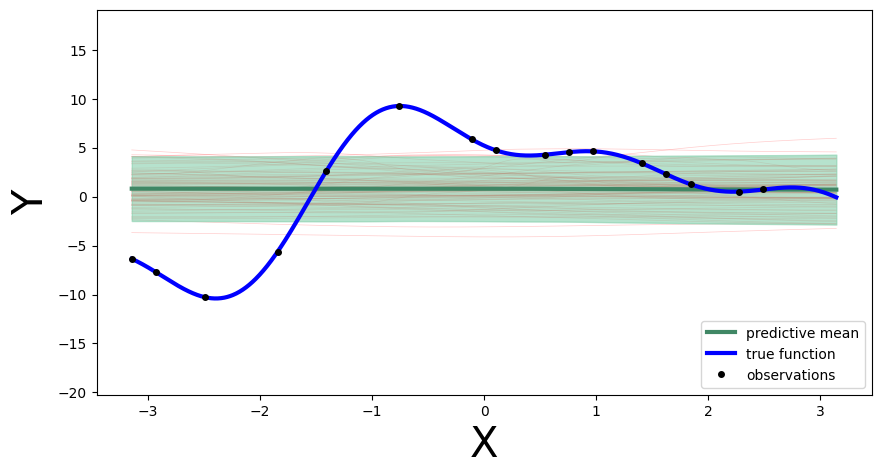

In [32]:
plot_predictions(layered, layered_guide, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:], pred_site="second/mu")